Code for IsoVita pipeline overview figure:

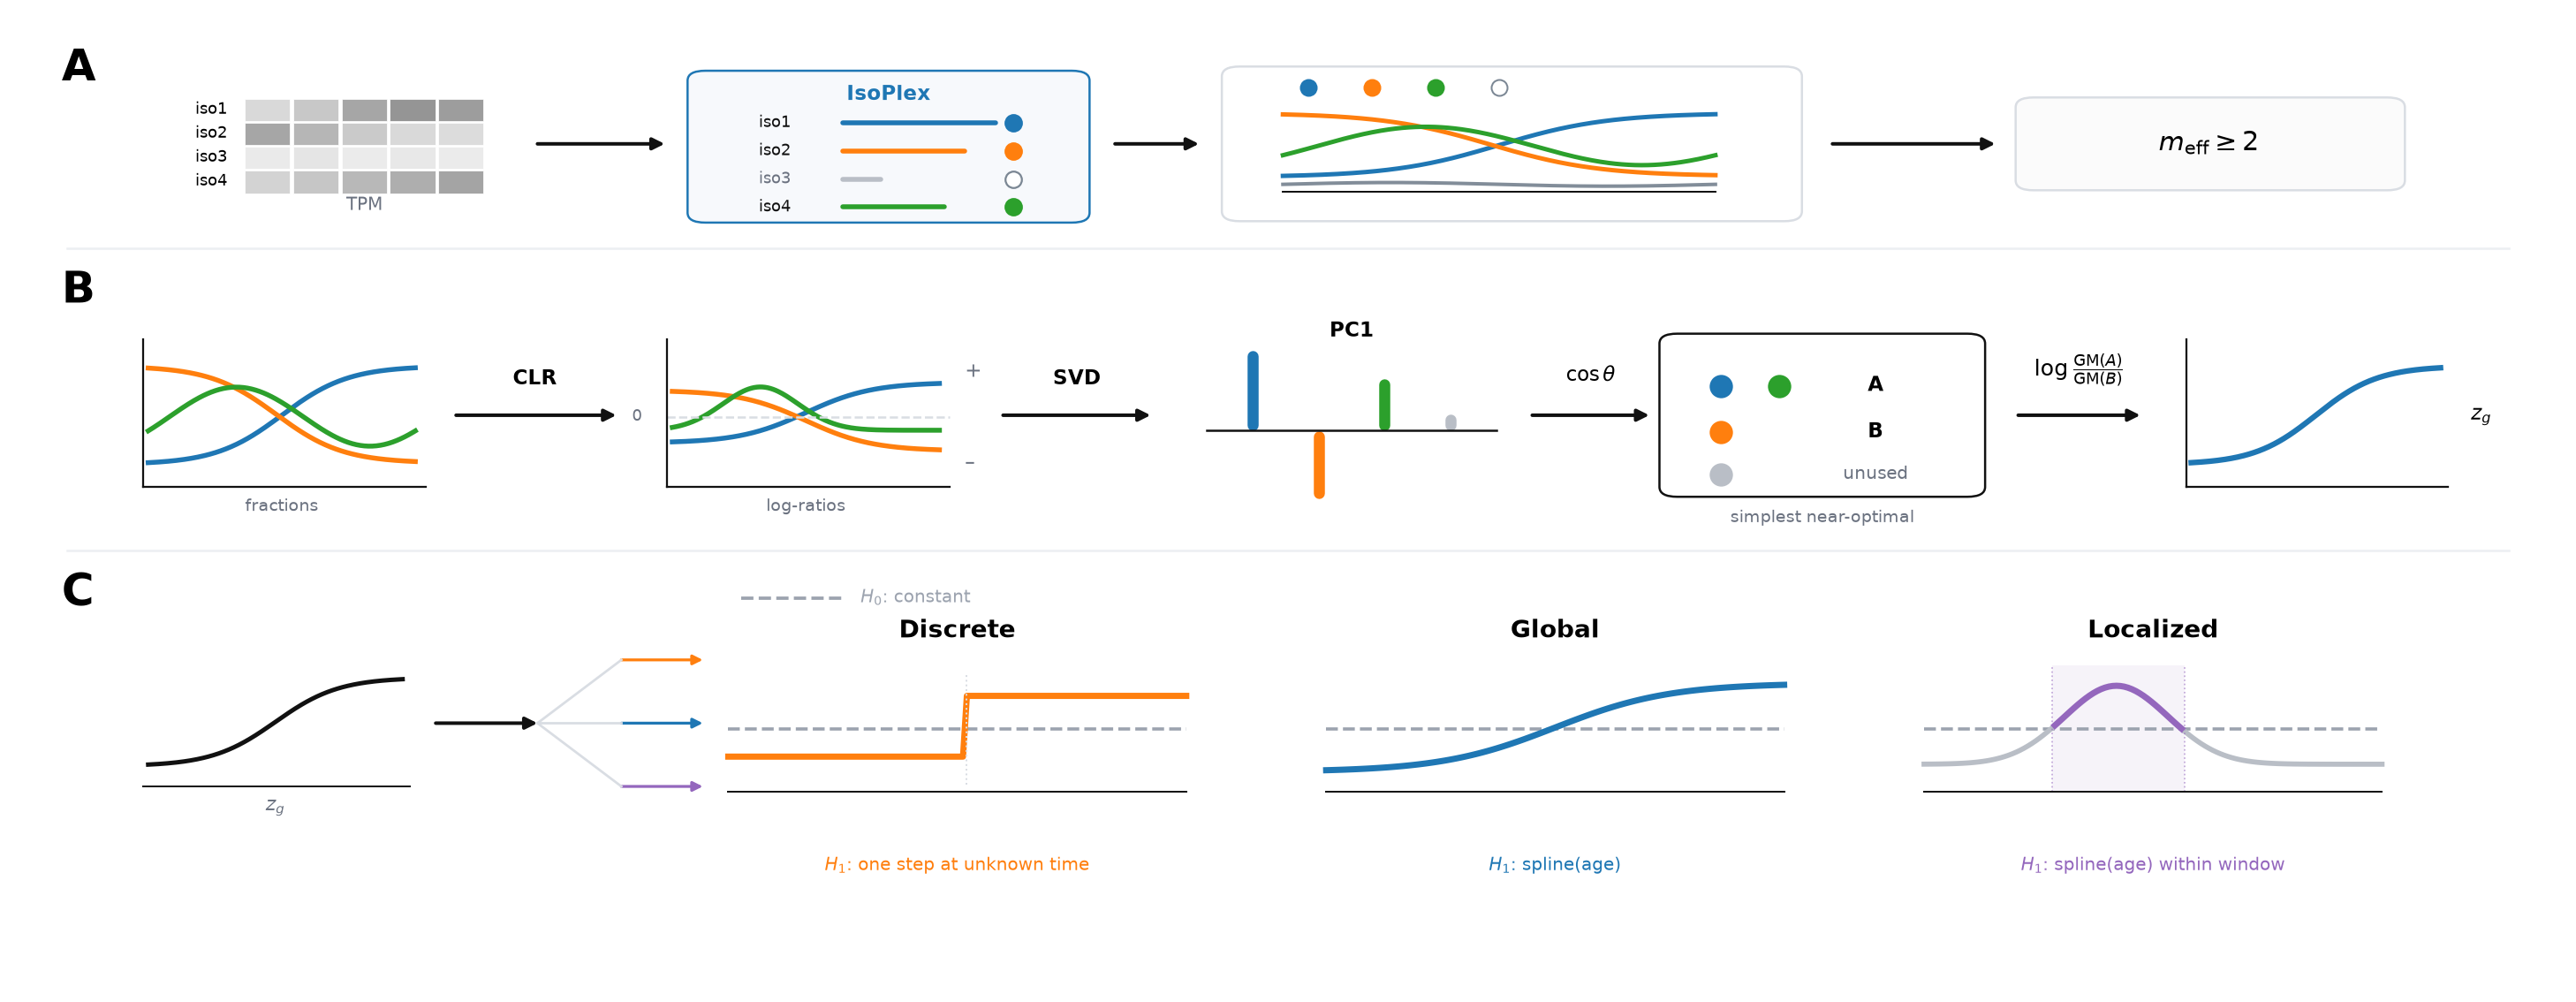

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

fig = plt.figure(figsize=(16, 6.1), dpi=180)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 1)
ax.set_ylim(0.31, 1)
ax.axis("off")

# palette
BLUE = "#1f77b4"
ORANGE = "#ff7f0e"
GREEN = "#2ca02c"
PURPLE = "#9467bd"
SLATE = "#7b8794"
GRAY = "#b9bec6"
LIGHT = "#d9dde3"
MUTED = "#6b7280"
INK = "#111111"
NULL = "#9ca3af"

def arrow(x1, y1, x2, y2, color=INK, lw=1.6, ms=11, alpha=1.0):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=ms,
        lw=lw,
        color=color,
        shrinkA=0,
        shrinkB=0,
        alpha=alpha
    ))

def rounded(x, y, w, h, fc="white", ec=LIGHT, lw=1.0, r=0.007):
    p = FancyBboxPatch(
        (x, y), w, h,
        boxstyle=f"round,pad=0.004,rounding_size={r}",
        fc=fc, ec=ec, lw=lw
    )
    ax.add_patch(p)
    return p

def panel(letter, y):
    ax.text(0.018, y, letter, fontsize=20, fontweight="bold", ha="left", va="top")

def dot(x, y, color, filled=True, s=90, lw=1.2):
    ax.scatter([x], [y], s=s, marker="o",
               facecolors=(color if filled else "white"),
               edgecolors=color, linewidths=lw, zorder=6)

def sigmoid(x):
    return 0.16 + 0.70/(1+np.exp(-8*(x-0.5)))

def decsig(x):
    return 0.86 - 0.69/(1+np.exp(-8*(x-0.48)))

x = np.linspace(0, 1, 200)

# ==========================================
# Panel A
# ==========================================
panel("A", 0.978)

mx, my, cw, ch = 0.090, 0.874, 0.019, 0.017
vals = np.array([
    [0.25,0.40,0.70,0.85,0.78],
    [0.70,0.56,0.38,0.25,0.22],
    [0.10,0.14,0.09,0.11,0.09],
    [0.30,0.42,0.54,0.63,0.72],
])
for r in range(4):
    for c in range(5):
        shade = str(0.96 - 0.44*vals[r,c])
        ax.add_patch(Rectangle(
            (mx+c*cw, my+(3-r)*ch),
            cw-0.0012, ch-0.0012,
            fc=shade, ec="white", lw=0.3
        ))
for r, lab in enumerate(["iso1","iso2","iso3","iso4"]):
    ax.text(mx-0.007, my+(3-r)*ch+ch/2, lab, fontsize=7.0, ha="right", va="center")
ax.text(mx+0.047, my-0.012, "TPM", fontsize=8.0, ha="center", color=MUTED)

arrow(0.205, 0.909, 0.255, 0.909)

rounded(0.268, 0.857, 0.150, 0.100, fc="#f7f9fc", ec=BLUE, lw=1.0)
ax.text(0.343, 0.944, "IsoPlex", fontsize=9.2, fontweight="bold", color=BLUE, ha="center", va="center")
rows_y = [0.924, 0.904, 0.884, 0.864]
labs = ["iso1", "iso2", "iso3", "iso4"]
cols = [BLUE, ORANGE, SLATE, GREEN]
fills = [True, True, False, True]
bar_lengths = [0.060, 0.048, 0.015, 0.040]
for yy, lab, cc, ff, bl in zip(rows_y, labs, cols, fills, bar_lengths):
    ax.text(0.292, yy, lab, fontsize=7.4, ha="left", va="center", color=MUTED if not ff else INK)
    ax.plot([0.325, 0.325+bl], [yy, yy], color=cc if ff else GRAY, lw=2.2, solid_capstyle="round")
    dot(0.392, yy, cc if ff else SLATE, filled=ff, s=55, lw=0.9)

arrow(0.432, 0.909, 0.465, 0.909)

rounded(0.478, 0.858, 0.220, 0.102, fc="white", ec=LIGHT, lw=1.0)
tx0, ty0, tw, th = 0.498, 0.875, 0.170, 0.065
low_curve = 0.08 + 0.02*np.sin(2*np.pi*x)
ax.plot(tx0 + tw*x, ty0 + th*low_curve, color=SLATE, lw=1.6, alpha=0.95)
ax.plot(tx0 + tw*x, ty0 + th*sigmoid(x), color=BLUE, lw=2.0)
ax.plot(tx0 + tw*x, ty0 + th*decsig(x), color=ORANGE, lw=2.0)
ax.plot(tx0 + tw*x, ty0 + th*(0.50 + 0.21*np.sin(2*np.pi*(x-0.08))), color=GREEN, lw=2.0)
ax.plot([tx0, tx0+tw], [ty0, ty0], color=INK, lw=0.8)
for xx, cc, ff in zip([0.508, 0.533, 0.558, 0.583], [BLUE, ORANGE, GREEN, SLATE], [True, True, True, False]):
    dot(xx, 0.949, cc, ff, s=52, lw=0.8)

arrow(0.714, 0.909, 0.778, 0.909)
rounded(0.790, 0.880, 0.145, 0.058, fc="#fbfbfb", ec=LIGHT)
ax.text(0.862, 0.909, r"$m_{\rm eff}\geq 2$", fontsize=12.0, ha="center", va="center")

ax.plot([0.02,0.98],[0.835,0.835], color="#eceff2", lw=1)

# ==========================================
# Panel B
# ==========================================
panel("B", 0.820)

x0, y0, w, h = 0.052, 0.665, 0.105, 0.100
ax.plot(x0+w*x, y0+h*sigmoid(x), color=BLUE, lw=2.2)
ax.plot(x0+w*x, y0+h*decsig(x), color=ORANGE, lw=2.2)
ax.plot(x0+w*x, y0+h*(0.50+0.21*np.sin(2*np.pi*(x-0.08))), color=GREEN, lw=2.2)
ax.plot([x0-0.002,x0+w+0.004],[y0,y0],color=INK,lw=0.9)
ax.plot([x0-0.002,x0-0.002],[y0,y0+h+0.005],color=INK,lw=0.9)
ax.text(x0+w/2, y0-0.017, "fractions", fontsize=7.5, ha="center", color=MUTED)

arrow(0.173,0.716,0.236,0.716)
ax.text(0.204,0.738,"CLR",fontsize=9.2,fontweight="bold",ha="center")

x0 = 0.258
clr1 = -0.65 + 1.40*sigmoid(x)
clr2 =  0.65 - 1.40*sigmoid(x)
clr3 =  0.70*np.exp(-((x-0.33)/0.20)**2) - 0.22
def map_clr(y):
    return 0.5 + 0.44*y

ax.plot(x0+w*x, y0+h*map_clr(clr1), color=BLUE, lw=2.2)
ax.plot(x0+w*x, y0+h*map_clr(clr2), color=ORANGE, lw=2.2)
ax.plot(x0+w*x, y0+h*map_clr(clr3), color=GREEN, lw=2.2)
ax.plot([x0-0.002,x0+w+0.004],[y0+0.050,y0+0.050],color=LIGHT,lw=1.0,ls="--")
ax.plot([x0-0.002,x0+w+0.004],[y0,y0],color=INK,lw=0.9)
ax.plot([x0-0.002,x0-0.002],[y0,y0+h+0.005],color=INK,lw=0.9)
ax.text(x0-0.012, y0+0.050, "0", fontsize=7.0, color=MUTED, ha="right", va="center")
ax.text(x0+w/2, y0-0.017, "log-ratios", fontsize=7.5, ha="center", color=MUTED)
ax.text(x0+w+0.010, y0+0.082, "+", fontsize=9, color=MUTED, ha="left", va="center")
ax.text(x0+w+0.010, y0+0.017, "–", fontsize=9, color=MUTED, ha="left", va="center")

arrow(0.388,0.716,0.446,0.716)
ax.text(0.417,0.738,"SVD",fontsize=9.2,fontweight="bold",ha="center")

base_y = 0.705
loading_x = [0.486, 0.512, 0.538, 0.564]
loading_v = [0.82, -0.67, 0.48, 0.06]
loading_c = [BLUE, ORANGE, GREEN, GRAY]
gap = 0.004
scale = 0.060
for xx, vv, cc in zip(loading_x, loading_v, loading_c):
    if vv >= 0:
        y_start = base_y + gap
        y_end = y_start + scale*vv
    else:
        y_start = base_y - gap
        y_end = y_start + scale*vv
    ax.plot([xx,xx],[y_start,y_end],color=cc,lw=5,solid_capstyle="round")
ax.plot([0.468,0.582],[base_y,base_y],color=INK,lw=1.0)
ax.text(0.525,0.772,"PC1",fontsize=9.0,fontweight="bold",ha="center")

arrow(0.596, 0.716, 0.642, 0.716)
ax.text(0.619, 0.740, r"$\cos\theta$", fontsize=9.0, ha="center")

rounded(0.650,0.662,0.120,0.108,fc="white",ec=INK,lw=1.0)
dot(0.670,0.737,BLUE,True,s=95,lw=0.8)
dot(0.693,0.737,GREEN,True,s=95,lw=0.8)
ax.text(0.731,0.737,"A",fontsize=9.0,ha="center",va="center",fontweight="bold")
dot(0.670,0.704,ORANGE,True,s=95,lw=0.8)
ax.text(0.731,0.704,"B",fontsize=9.0,ha="center",va="center",fontweight="bold")
dot(0.670,0.674,GRAY,True,s=95,lw=0.8)
ax.text(0.731,0.674,"unused",fontsize=7.8,ha="center",va="center",color=MUTED)
ax.text(0.710,0.640,"simplest near-optimal",fontsize=7.6,ha="center",color=MUTED)

arrow(0.787,0.716,0.835,0.716)
ax.text(0.811,0.744,r"$\log\frac{\mathrm{GM}(A)}{\mathrm{GM}(B)}$",fontsize=10.2,ha="center")

x0 = 0.855
feature_w = 0.098
ax.plot(x0+feature_w*x, y0+h*sigmoid(x), color=BLUE, lw=2.5)
ax.plot([x0-0.002,x0+feature_w+0.003],[y0,y0],color=INK,lw=0.9)
ax.plot([x0-0.002,x0-0.002],[y0,y0+h+0.005],color=INK,lw=0.9)
ax.text(0.965,0.716,r"$z_g$",fontsize=9.2,ha="left",va="center")

ax.plot([0.02,0.98],[0.620,0.620], color="#eceff2", lw=1)

# ==========================================
# Panel C
# ==========================================
panel("C", 0.605)

src_x, src_y, src_w, src_h = 0.052, 0.452, 0.100, 0.090
ax.plot(src_x+src_w*x, src_y+src_h*sigmoid(x), color=INK, lw=2.0)
ax.plot([src_x-0.002,src_x+src_w+0.003],[src_y,src_y],color=INK,lw=0.8)
ax.text(src_x+src_w/2, src_y-0.017, r"$z_g$", fontsize=8.7, ha="center", color=MUTED)

arrow(0.165,0.497,0.205,0.497)
for by, cc in zip([0.542,0.497,0.452],[ORANGE,BLUE,PURPLE]):
    ax.plot([0.205,0.238],[0.497,by],color=LIGHT,lw=1.1)
    arrow(0.238,by,0.270,by,color=cc,lw=1.3,ms=9)

ax.plot([0.285,0.325],[0.586,0.586],color=NULL,lw=1.5,ls="--")
ax.text(0.332,0.586,r"$H_0$: constant",fontsize=8.0,color=NULL,va="center")

def model_plot(x0, y0, w, h, mode, color):
    xx = np.linspace(0,1,120)
    null = np.full_like(xx,0.50)
    ax.plot(x0+w*xx, y0+h*null, color=NULL, lw=1.45, ls="--")
    if mode == "step":
        yy = np.where(xx<0.52,0.28,0.76)
        ax.plot(x0+w*xx, y0+h*yy, color=color, lw=2.8)
        ax.plot([x0+w*0.52,x0+w*0.52],[y0+0.06*h,y0+0.94*h], color=LIGHT,lw=0.8,ls=":")
    elif mode == "global":
        yy = sigmoid(xx)
        ax.plot(x0+w*xx, y0+h*yy, color=color, lw=2.8)
    elif mode == "local":
        lo,hi = 0.28,0.57
        full = 0.22 + 0.62*np.exp(-((xx-0.42)/0.16)**2)
        ax.add_patch(Rectangle((x0+w*lo,y0),w*(hi-lo),h,fc=color,ec="none",alpha=0.08))
        ax.plot(x0+w*xx[xx<lo], y0+h*full[xx<lo], color=GRAY, lw=2.3)
        m = (xx>=lo)&(xx<=hi)
        ax.plot(x0+w*xx[m], y0+h*full[m], color=color, lw=2.8)
        ax.plot(x0+w*xx[xx>hi], y0+h*full[xx>hi], color=GRAY, lw=2.3)
        ax.plot([x0+w*lo,x0+w*lo],[y0,y0+h],color=color,lw=0.7,ls=":",alpha=0.55)
        ax.plot([x0+w*hi,x0+w*hi],[y0,y0+h],color=color,lw=0.7,ls=":",alpha=0.55)
    ax.plot([x0,x0+w],[y0,y0],color=INK,lw=0.8)

cols_x=[0.280,0.515,0.750]
titles=["Discrete","Global","Localized"]
modes=["step","global","local"]
cols=[ORANGE,BLUE,PURPLE]

for cx,title,mode,cc in zip(cols_x,titles,modes,cols):
    ax.text(cx+0.090,0.558,title,fontsize=11.0,fontweight="bold",ha="center")
    model_plot(cx,0.448,0.180,0.090,mode,cc)

ax.text(0.370,0.392,r"$H_1$: one step at unknown time",fontsize=8.0,ha="center",color=ORANGE)
ax.text(0.605,0.392,r"$H_1$: spline(age)",fontsize=8.0,ha="center",color=BLUE)
ax.text(0.840,0.392,r"$H_1$: spline(age) within window",fontsize=8.0,ha="center",color=PURPLE)

#plt.savefig("isovita_figure2_graphical_final.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()